# Exploración de datos de OT Consulting (notebook individual)

| Dato | Detalle |
| --- | --- |
| Alumno | Diego Perez Sánchez · A01236912 |
| Materia | Soporte analítico para la toma de decisiones · Grupo 301 |
| Entrega | Avance Reto Etapa 2: Análisis y Exploración de los Datos |
| Fuente | `diegoOT_backup_2026-11-17_sin_credenciales.json` (respaldo del sistema de OTC, sin usuarios ni contraseñas) |
| Fecha de corte | 17 de noviembre de 2026 |

La exploración base del equipo está en `diegoOT_EDA_equipo.ipynb`. Este cuaderno es mi exploración individual: reviso el respaldo tabla por tabla y columna por columna, y respondo en Markdown lo que me interesa revisar como director de OT.

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
CORTE = pd.Timestamp('2026-11-17')
with open('diegoOT_backup_2026-11-17_sin_credenciales.json', encoding='utf-8') as f:
    raw = json.load(f)
print('Colecciones en el respaldo:', list(raw))

Colecciones en el respaldo: ['colaboradores', 'habilidades', 'roles', 'departamentos', 'matriz', 'clientes', 'asignaciones', 'activos', 'secuenciaOTC']


## 1. Carga de cada tabla en un DataFrame

In [2]:
colab = pd.DataFrame(raw['colaboradores'])
roles = pd.DataFrame(raw['roles'])
deptos = pd.DataFrame(raw['departamentos'])
habil = pd.DataFrame(raw['habilidades'])
activos = pd.DataFrame(raw['activos'])
# Asignaciones: una fila por colaborador-proyecto
asig = pd.DataFrame([{**p, 'uid_colaborador': a['uid_colaborador']} for a in raw['asignaciones'] for p in a['proyectos']])
asig[['id_proyecto','proyecto']] = asig['proyecto_val'].str.split('|', n=1, expand=True)
asig['proyecto'] = asig['proyecto'].str.strip()
# Clientes: una fila por proyecto
proy = pd.DataFrame([{**p, 'cliente': c['nombre'], 'industria': c['industria'], 'estatus_cliente': c['estatus']} for c in raw['clientes'] for p in c.get('proyectos', [])])
# Matriz de habilidades: una fila por colaborador-habilidad
matriz = pd.DataFrame([{'uid_colaborador': m['uid_colaborador'], 'codigo': k, 'nivel': v} for m in raw['matriz'] for k, v in m['habilidades'].items()])
# Equipos: una fila por asignación de equipo
eq_asig = pd.DataFrame([{**x, 'codigo': a['codigo']} for a in raw['activos'] for x in a.get('asignaciones', [])])
tablas = {'colaboradores': colab, 'roles': roles, 'departamentos': deptos, 'habilidades': habil, 'activos (equipos)': activos,
          'asignaciones': asig, 'proyectos (clientes)': proy, 'matriz habilidades': matriz, 'equipos asignados': eq_asig}

## 2. Inventario: filas, columnas y celdas vacías por tabla

In [3]:
def vacio(s):
    return s.isna() | s.astype(str).str.strip().isin(['', 'nan', 'None', '[]', '{}'])
inv = pd.DataFrame([{'tabla': n, 'filas': len(t), 'columnas': t.shape[1],
                     'celdas_vacias_%': round(t.apply(vacio).values.mean()*100, 1)} for n, t in tablas.items()])
inv

,tabla,filas,columnas,celdas_vacias_%
0,colaboradores,107,47,11.1
1,roles,55,7,0.5
2,departamentos,6,7,28.6
3,habilidades,71,6,0.0
4,activos (equipos),123,17,21.5
5,asignaciones,31,9,8.6
6,proyectos (clientes),12,11,37.1
7,matriz habilidades,1539,3,0.0
8,equipos asignados,91,5,37.6


## 3. Perfil columna por columna
Para cada columna: tipo, vacíos, valores distintos y el valor más frecuente. En los datos personales no muestro el valor.

In [4]:
SENSIBLES = {'nombre','ben_nombre','ben_parentesco','email','telefono','domicilio','curp','rfc','nss','fechanac','uid','uid_colaborador','uid_colab','serie','contacto_nom','contacto_email','contacto_tel','resp_cli','email_cli','tel_cli'}
def perfil(t):
    filas = []
    for c in t.columns:
        s = t[c].astype(str)
        top = s[~vacio(t[c])].value_counts()
        filas.append({'columna': c, 'tipo': str(t[c].dtype), 'vacios': int(vacio(t[c]).sum()), 'distintos': t[c].astype(str).nunique(),
                      'mas_frecuente': '(dato personal)' if c in SENSIBLES else (top.index[0][:40] if len(top) else ''),
                      'veces': int(top.iloc[0]) if len(top) else 0})
    return pd.DataFrame(filas)
for n, t in tablas.items():
    print(f'\n=== {n} ({len(t)} filas) ===')
    print(perfil(t).to_string(index=False))


=== colaboradores (107 filas) ===
               columna    tipo  vacios  distintos         mas_frecuente  veces
                  curp     str       0          1       (dato personal)    107
     aviso_manutencion     str       2          4             Pendiente     95
                nombre     str       0        107       (dato personal)      1
                 depto     str      95          3 Operaciones y Soporte     11
                  sgmm     str       6         11               METLIFE     36
     sueldo_neto_total float64       0         66                   0.0     25
             doc_banco     str       0          2                    SI     71
                 email     str       0          1       (dato personal)    107
   sueldo_complementos float64       0         11                   0.0     97
            ben_nombre     str       3          6       (dato personal)     98
       aviso_infonavit     str       0          3             Pendiente     95
                 

**Lo que veo en el perfil.** Muchos campos se repiten con el mismo valor: puesto PENDIENTE, fecha 1990-01-01, teléfono 999999999, domicilio "conocida", CURP con X. Para mí esto indica que buena parte del respaldo son **datos de prueba o de relleno**, no información real. Por eso no tiene mucho sentido juzgar cada número como un error de captura. Lo importante es separar lo real de lo de prueba antes de analizar.

## 4. Valores de prueba o de relleno

In [5]:
act = colab[colab['estatus'] == 'Activo']
pruebas = pd.DataFrame([
    ('colaboradores', 'puesto = PENDIENTE (activos)', (act['puesto'] == 'PENDIENTE').sum(), len(act)),
    ('colaboradores', 'telefono = 999999999', (colab['telefono'].astype(str) == '999999999').sum(), len(colab)),
    ('colaboradores', 'domicilio = conocida', (colab['domicilio'].astype(str).str.lower().str.strip() == 'conocida').sum(), len(colab)),
    ('colaboradores', 'CURP con X', colab['curp'].astype(str).str.contains('XXXX').sum(), len(colab)),
    ('colaboradores', 'correo genérico', (colab['email'] == 'colaborador@otconsulting.com.mx').sum(), len(colab)),
    ('colaboradores', 'sueldo total integrado en 0 o vacío (activos)', (pd.to_numeric(act['sueldo_total_integrado'], errors='coerce').fillna(0) <= 0).sum(), len(act)),
    ('asignaciones', 'rol = PENDIENTE', (asig['rol'] == 'PENDIENTE').sum(), len(asig)),
    ('asignaciones', 'inicio = 1990-01-01', (asig['inicio'] == '1990-01-01').sum(), len(asig)),
    ('asignaciones', 'sin fecha de fin', vacio(asig['fin']).sum(), len(asig)),
    ('asignaciones', 'proyecto = Asignación indefinida', (asig['proyecto'] == 'Asignación indefinida').sum(), len(asig)),
    ('proyectos', 'sin PM de OTC', vacio(proy['pm_otc']).sum(), len(proy)),
    ('equipos', 'costo = 0', (pd.to_numeric(activos['costo'], errors='coerce').fillna(0) == 0).sum(), len(activos)),
    ('equipos asignados', 'inicio = 1990-01-01', (eq_asig['f_ini'] == '1990-01-01').sum(), len(eq_asig)),
], columns=['tabla', 'valor de prueba o relleno', 'registros', 'de'])
pruebas['%'] = (pruebas['registros'] / pruebas['de'] * 100).round(0)
pruebas

,tabla,valor de prueba o relleno,registros,de,%
0,colaboradores,puesto = PENDIENTE (activos),29,75,39.0
1,colaboradores,telefono = 999999999,107,107,100.0
2,colaboradores,domicilio = conocida,107,107,100.0
3,colaboradores,CURP con X,107,107,100.0
4,colaboradores,correo genérico,107,107,100.0
5,colaboradores,sueldo total integrado en 0 o vacío (activos),5,75,7.0
6,asignaciones,rol = PENDIENTE,29,31,94.0
7,asignaciones,inicio = 1990-01-01,21,31,68.0
8,asignaciones,sin fecha de fin,24,31,77.0
9,asignaciones,proyecto = Asignación indefinida,18,31,58.0


## 5. ¿Quién está trabajando y dónde?

Colaboradores activos: 75
Con al menos una asignación: 30  |  Sin asignación registrada: 45
proyecto
Asignación indefinida    18
Soporte AMS Manufacta     5
Migración eBs             5
Marazzi                   3


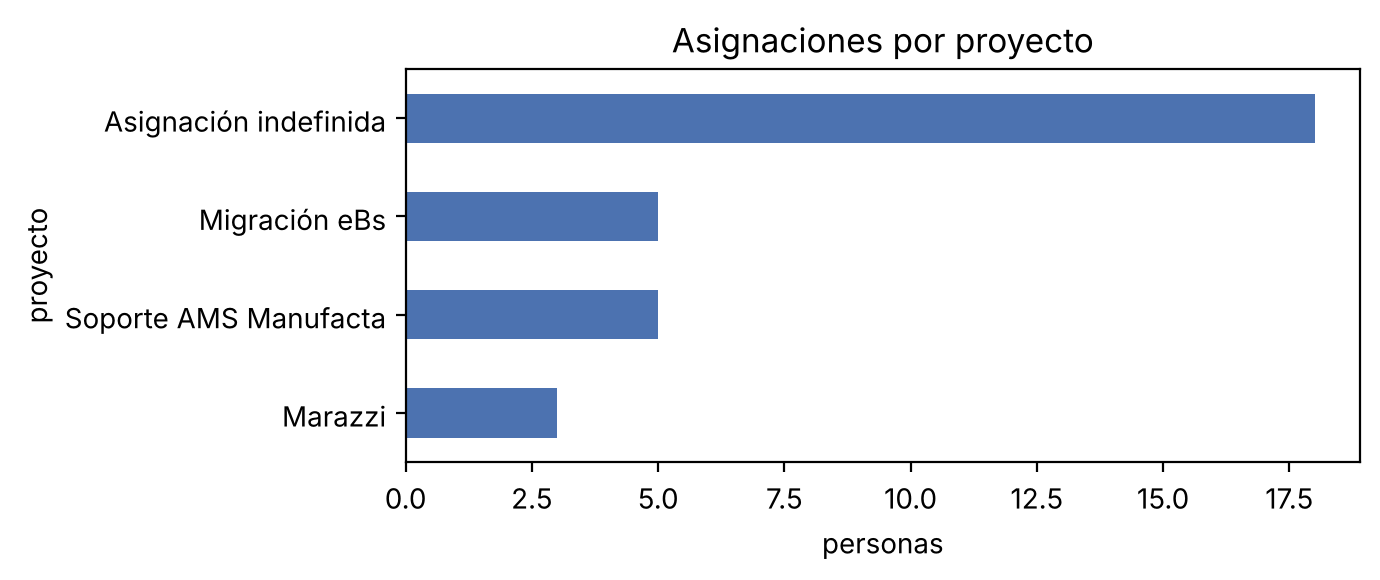

In [6]:
act_ids = set(act['uid'])
con_asig = act_ids & set(asig['uid_colaborador'])
print(f'Colaboradores activos: {len(act_ids)}')
print(f'Con al menos una asignación: {len(con_asig)}  |  Sin asignación registrada: {len(act_ids - con_asig)}')
dist = asig['proyecto'].value_counts()
print(dist.to_string())
ax = dist.sort_values().plot.barh(figsize=(7, 3), color='#4C72B0', title='Asignaciones por proyecto')
ax.set_xlabel('personas'); plt.tight_layout(); plt.show()

**Respuesta.** De los 75 activos solo 30 aparecen en alguna asignación, y de esas 18 dicen "Asignación indefinida" en lugar de un proyecto. Así que hoy OT no puede saber con los datos quién trabaja dónde. Es lo primero que necesitaría tener bajo control.

## 6. ¿Cuándo termina cada asignación y a quién contacto?

In [7]:
asig['fin_dt'] = pd.to_datetime(asig['fin'], errors='coerce')
print('Asignaciones con fecha de fin:', asig['fin_dt'].notna().sum(), 'de', len(asig))
print(asig.loc[asig['fin_dt'].notna(), ['proyecto', 'rol', 'inicio', 'fin']].to_string(index=False))
print('\nProyectos registrados:', len(proy))
print('Con PM de OTC:', (~vacio(proy['pm_otc'])).sum(), '| Con responsable del cliente:', (~vacio(proy['resp_cli'])).sum(),
      '| Con correo del cliente:', (~vacio(proy['email_cli'])).sum(), '| Con teléfono del cliente:', (~vacio(proy['tel_cli'])).sum())

Asignaciones con fecha de fin: 7 de 31
     proyecto       rol     inicio        fin
      Marazzi PENDIENTE 2026-01-01 2027-01-01
      Marazzi PENDIENTE 2026-01-01 2027-01-01
      Marazzi PENDIENTE 2026-01-01 2027-01-01
Migración eBs PENDIENTE 2026-10-13 2027-07-01
Migración eBs PENDIENTE 2026-10-13 2027-07-01
Migración eBs PENDIENTE 2026-10-13 2027-07-01
Migración eBs PENDIENTE 2026-10-13 2028-07-01

Proyectos registrados: 12
Con PM de OTC: 6 | Con responsable del cliente: 6 | Con correo del cliente: 1 | Con teléfono del cliente: 1


**Respuesta.** Casi ninguna asignación tiene fecha de fin, entonces no se puede anticipar quién se va a liberar. Tampoco es fácil saber a quién llamar: la mitad de los proyectos no tiene PM de OTC y solo 1 de 12 tiene correo y teléfono del cliente. Para tener control, cada asignación debería tener fecha de fin y cada proyecto un contacto.

## 7. ¿Cuánta antigüedad tienen los colaboradores?

count    74.0
mean      5.7
std       5.0
min       0.1
25%       2.1
50%       3.9
75%       9.3
max      23.6


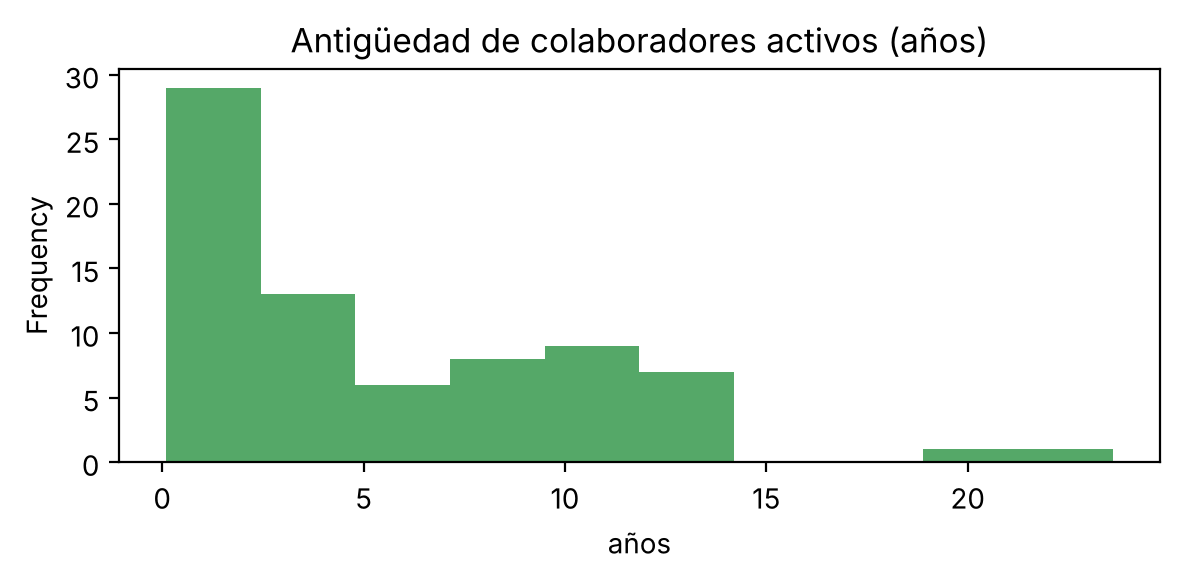

In [8]:
act = act.copy()
act['fechainc_dt'] = pd.to_datetime(act['fechainc'], errors='coerce')
act['antiguedad_anios'] = ((CORTE - act['fechainc_dt']).dt.days / 365.25).round(1)
print(act['antiguedad_anios'].describe().round(1).to_string())
ax = act['antiguedad_anios'].plot.hist(bins=10, figsize=(6, 3), color='#55A868', title='Antigüedad de colaboradores activos (años)')
ax.set_xlabel('años'); plt.tight_layout(); plt.show()

## 8. ¿Cuánto tiempo llevan las laptops y quién las tiene?

tipo
Laptop     122
Monitor      1

Edad de los equipos (años):
count    53.0
mean      3.2
std       1.9
min       1.2
25%       2.1
50%       2.8
75%       3.9
max       9.6

Equipos con más de 3 años: 22 de 53 con fecha de compra
Equipos sin fecha de garantía: 123 de 123

Equipos asignados hoy: 81
estatus
Activo    72
Baja       9


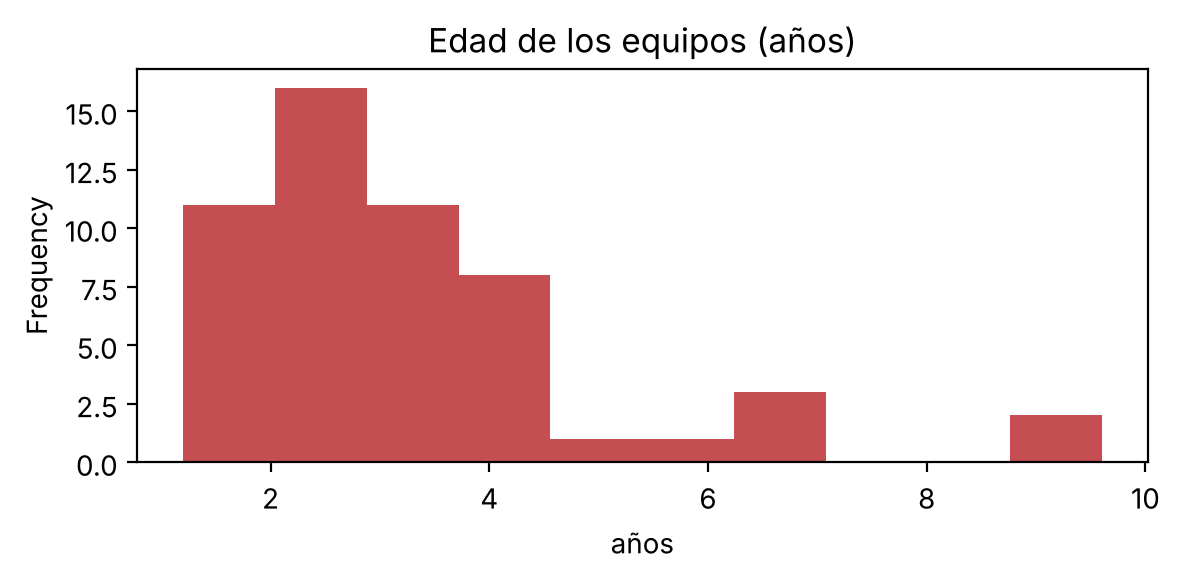

In [9]:
activos['fcompra_dt'] = pd.to_datetime(activos['fcompra'], errors='coerce')
activos['edad_anios'] = ((CORTE - activos['fcompra_dt']).dt.days / 365.25).round(1)
print(activos['tipo'].value_counts().to_string())
print('\nEdad de los equipos (años):'); print(activos['edad_anios'].describe().round(1).to_string())
print('\nEquipos con más de 3 años:', (activos['edad_anios'] > 3).sum(), 'de', activos['edad_anios'].notna().sum(), 'con fecha de compra')
print('Equipos sin fecha de garantía:', vacio(activos['fgarantia']).sum(), 'de', len(activos))
# Último responsable de cada equipo y su estatus
ult = eq_asig[vacio(eq_asig['f_fin'])].merge(colab[['uid', 'estatus']], left_on='uid_colab', right_on='uid', how='left')
print('\nEquipos asignados hoy:', ult['codigo'].nunique())
print(ult['estatus'].fillna('colaborador no encontrado').value_counts().to_string())
ax = activos['edad_anios'].plot.hist(bins=10, figsize=(6, 3), color='#C44E52', title='Edad de los equipos (años)')
ax.set_xlabel('años'); plt.tight_layout(); plt.show()

**Respuesta.** Sí se puede saber cuántos años lleva cada laptop por su fecha de compra. Lo que no se puede saber es si sigue en buen estado, porque el sistema no guarda el estado físico ni revisiones. También aparecen equipos que siguen a nombre de personas dadas de baja, y eso es un riesgo de control.

## 9. Ciberseguridad

In [10]:
print('¿El respaldo publicado trae la sección usuarios?', 'usuarios' in raw)
sens = ['curp', 'rfc', 'nss', 'telefono', 'domicilio', 'email', 'ben_nombre', 'fechanac']
print(pd.DataFrame({'campo': sens, 'con dato': [(~vacio(colab[c])).sum() for c in sens]}).to_string(index=False))

¿El respaldo publicado trae la sección usuarios? False
     campo  con dato
      curp       107
       rfc       107
       nss       107
  telefono       107
 domicilio       107
     email       107
ben_nombre       104
  fechanac       106


**Respuesta.** El respaldo original del sistema traía una sección `usuarios` con las cuentas de administrador y sus contraseñas en texto plano (6 cuentas). Por eso la quité antes de subir el archivo a este repositorio. Además, el sistema guarda datos personales (CURP, RFC, NSS, beneficiarios), así que para mí la ciberseguridad es una prioridad: contraseñas cifradas, acceso por rol y no compartir respaldos completos.

## 10. Dinero: sueldos contra ingresos

In [11]:
act['sti'] = pd.to_numeric(act['sueldo_total_integrado'], errors='coerce')
validos = act[act['sti'] > 0]  # regla: sueldo 0 o vacío no se usa en gráficas ni analítica
print(f'Activos con sueldo válido: {len(validos)} de {len(act)}')
print(f'Nómina mensual (sueldo total integrado): ${validos["sti"].sum():,.0f}')
print(f'Sueldo total integrado promedio: ${validos["sti"].mean():,.0f}')
print('Columnas de ingresos o tarifas en el respaldo:', [c for t in tablas.values() for c in t.columns if any(k in c.lower() for k in ['ingreso', 'tarifa', 'factura', 'precio'])])

Activos con sueldo válido: 70 de 75
Nómina mensual (sueldo total integrado): $3,918,864
Sueldo total integrado promedio: $55,984
Columnas de ingresos o tarifas en el respaldo: []


**Respuesta.** El número que yo revisaría cada mes es el dinero que entra contra lo que se paga de sueldos. Los sueldos sí están en los datos, pero no hay ninguna columna de ingresos, tarifas o facturación. Sin ese dato no se puede saber si OT gana o pierde con cada proyecto.

## 11. Conclusión

- Gran parte del respaldo son datos de prueba o de relleno; antes de analizar hay que separarlos.
- Hoy OT no puede saber con certeza quién trabaja dónde, cuándo termina ni a quién contactar.
- Sí se puede medir la antigüedad de colaboradores y laptops, pero no el estado de los equipos.
- Las contraseñas en texto plano son el hallazgo más urgente.
- Falta el dato de ingresos para comparar contra la nómina.
- Pregunta abierta para OT: si un consultor está en dos proyectos, ¿cómo se reparte su sueldo entre ellos?